# 📊 Retail Sales — Interactive Business Dashboard
**Apex Lark Data Analytics Internship · Task Day 10** &nbsp;|&nbsp; Interactive Data Visualization & Business Dashboard Using Python

**Business question:** *How is the retail business performing — where do sales and profit come from, who are the best customers, and what should management do next?*

| Section | Contents |
|---|---|
| **1. Load & Prepare** | Import with Pandas, data-quality audit, cleaning, feature engineering |
| **2. KPI Metrics** | Sales, profit, orders, AOV, customers, products, margin |
| **3. Dashboard** | Business Overview · Sales · Customers · Products · Profit (Matplotlib + Seaborn) |
| **4. Advanced Visuals** | Correlation heatmap, regression scatter, violin plot, distribution plots |
| **5. One-page Dashboard** | All key panels consolidated into a single figure |
| **6. Insights Report** | Key findings, data-driven recommendations, data limitations |

> **Assumptions** — (1) The dataset has no currency field; amounts are shown in **₹** because all 20 cities are Indian. (2) *Cancelled* orders earn no revenue and are excluded from sales/profit KPIs; *Returned* orders are kept but tracked separately as a risk metric.

## 0. Setup

In [1]:
import json, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from matplotlib.patches import FancyBboxPatch
from matplotlib.gridspec import GridSpec
import seaborn as sns
from IPython.display import display, Markdown

warnings.filterwarnings("ignore")
pd.set_option("display.float_format", "{:,.2f}".format)
pd.set_option("display.max_columns", 30)

# ---- Paths -----------------------------------------------------------------
DATA_PATH = Path("data/sales_data.csv")
FIG_DIR, OUT_DIR = Path("figures"), Path("outputs")
for d in (FIG_DIR, OUT_DIR):
    d.mkdir(exist_ok=True)

# ---- Visual theme ----------------------------------------------------------
NAVY, BLUE, TEAL, ORANGE, RED, GREY = "#1F3A5F", "#2E75B6", "#2A9D8F", "#F4A261", "#E76F51", "#8D99AE"
CAT_COLORS = dict(zip(
    ["Electronics", "Furniture", "Sports", "Clothing", "Books", "Beauty", "Groceries"],
    ["#1F3A5F", "#2E75B6", "#2A9D8F", "#F4A261", "#E9C46A", "#E76F51", "#8D99AE"]))
sns.set_theme(style="whitegrid", context="notebook", font_scale=1.0)
plt.rcParams.update({"figure.dpi": 110, "axes.titlesize": 13, "axes.titleweight": "bold",
                     "axes.labelsize": 10.5, "axes.spines.top": False, "axes.spines.right": False})

def inr(x, pos=None):
    """Format a number as ₹ with K / M suffix (also used as an axis formatter)."""
    sign, x = ("-" if x < 0 else ""), abs(x)
    if x >= 1e6: return f"{sign}₹{x/1e6:,.1f}M"
    if x >= 1e3: return f"{sign}₹{x/1e3:,.0f}K"
    return f"{sign}₹{x:,.0f}"

def takeaway(text):
    """Render a short, data-driven interpretation under a chart."""
    display(Markdown("> 💡 **Takeaway:** " + text))

def save_fig(fig, name):
    """Tidy, save to /figures (used later in the PDF report) and display."""
    fig.savefig(FIG_DIR / f"{name}.png", dpi=150, bbox_inches="tight", facecolor="white")
    plt.show()

---
# 1. Load and Prepare the Dataset
## 1.1 Import the dataset

In [2]:
raw = pd.read_csv(DATA_PATH)
print(f"Raw dataset: {raw.shape[0]:,} rows × {raw.shape[1]} columns")
raw.head()

Raw dataset: 4,310 rows × 21 columns


,order_id,order_date,customer_id,customer_name,age,gender,region,city,product_category,product_name,quantity,unit_price,discount_pct,sales_amount,profit,shipping_cost,payment_method,customer_satisfaction,return_flag,order_status,days_to_ship
0,ORD-03903,2024-08-15,CUST32603,Aarav Mehta,39.00,Other,Central,Raipur,Groceries,Sugar,8.00,346.32,NaN,"4,043.14",289.18,56.04,Debit Card,NaN,True,Returned,7.00
1,ORD-02198,2022-08-16,CUST07881,Sanjay Verma,28.00,Male,West,Mumbai,Beauty,Sunscreen,8.00,858.66,0.08,"9,147.31","5,355.56",64.49,Debit Card,5.00,False,Delivered,2.00
2,ORD-01348,2021-08-29,CUST49296,Pooja Sharma,41.00,Other,West,Surat,Furniture,Sofa,4.00,"25,941.32",0.14,"110,156.97","36,956.51",67.65,Debit Card,4.00,False,Delivered,5.00
3,ORD-02076,2022-07-05,CUST05587,Priya Reddy,29.00,Other,West,Ahmedabad,Furniture,Bed Frame,9.00,"22,071.92",0.17,"262,066.11","66,644.99",54.47,EMI,3.00,False,Delivered,4.00
4,ORD-00287,2020-05-07,CUST58035,Ritu Sharma,9.00,Male,Central,Nagpur,Groceries,Cooking Oil,1.00,320.06,0.31,323.95,31.38,48.81,Net Banking,4.00,False,Pending,4.00


## 1.2 Verify data quality *before* visualizing
A quick audit shows the file is far from analysis-ready. Each issue found is quantified below and fixed in section 1.3.

In [3]:
audit = pd.DataFrame({
    "dtype": raw.dtypes.astype(str),
    "missing": raw.isna().sum(),
    "missing_%": (raw.isna().mean() * 100).round(1),
    "unique": raw.nunique(),
})
display(audit)

body = raw.dropna(how="all")
issues = pd.DataFrame([
    ("Completely blank rows",                       int(raw.isna().all(axis=1).sum())),
    ("Exact duplicate orders",                      int(body.duplicated().sum())),
    ("Inconsistent gender labels (11 spellings)",   int(body.gender.nunique())),
    ("Inconsistent order_status casing",            int((body.order_status != body.order_status.str.title()).sum())),
    ("Order dates not in ISO format (3 formats)",   int((~body.order_date.str.match(r"^\d{4}-\d{2}-\d{2}$")).sum())),
    ("Impossible age (<18 or >90, incl. -7 and 999)", int(((body.age < 18) | (body.age > 90)).sum())),
    ("Impossible quantity (≤0)",                    int((body.quantity <= 0).sum())),
    ("Sentinel quantity = 999 (inflates revenue)",  int((body.quantity > 100).sum())),
    ("Impossible days_to_ship (<0 or >30)",         int(((body.days_to_ship < 0) | (body.days_to_ship > 30)).sum())),
    ("Negative shipping_cost",                      int((body.shipping_cost < 0).sum())),
], columns=["Issue", "Rows / values affected"])
issues

,dtype,missing,missing_%,unique
order_id,str,30,0.70,4200
order_date,str,30,0.70,1837
customer_id,str,30,0.70,4112
customer_name,str,30,0.70,400
age,float64,160,3.70,80
gender,str,30,0.70,11
region,str,30,0.70,5
city,str,30,0.70,20
product_category,str,30,0.70,7
product_name,str,30,0.70,42


,Issue,Rows / values affected
0,Completely blank rows,30
1,Exact duplicate orders,80
2,Inconsistent gender labels (11 spellings),11
3,Inconsistent order_status casing,156
4,Order dates not in ISO format (3 formats),273
5,"Impossible age (<18 or >90, incl. -7 and 999)",346
6,Impossible quantity (≤0),18
7,Sentinel quantity = 999 (inflates revenue),8
8,Impossible days_to_ship (<0 or >30),11
9,Negative shipping_cost,2


## 1.3 Clean the data
Every cleaning rule is explicit and logged so the process is reproducible.

| Problem | Treatment | Why |
|---|---|---|
| Blank rows, exact duplicates | Drop | Carry no / double-count information |
| Text labels (gender, status) | Standardize | Prevent one category splitting into many |
| 3 mixed date formats | Parse each format; slash dates read as **DD/MM/YYYY** | 86 slash dates have a first part >12, never the second, so day-first is certain |
| `quantity` = 999 | Drop rows | Sentinel value; inflates single orders to ₹17M and distorts every total |
| `quantity` ≤ 0 or missing | Median quantity of the same product | Orders must have ≥1 unit |
| Impossible `age`, `days_to_ship`, negative `shipping_cost` | Set to missing, then median-impute | Values are physically impossible |
| Missing `discount_pct` | Median of the product category | Keeps category-level behaviour |
| Missing `customer_satisfaction` | **Left blank** | Inventing a customer's opinion would bias the average |
| Same `customer_id`, different names | Use the most frequent name | One ID = one customer |

In [4]:
GENDER_MAP = {"male": "Male", "m": "Male", "female": "Female", "f": "Female", "other": "Other"}

def parse_dates(s: pd.Series) -> pd.Series:
    """Parse the three date formats present in the file."""
    s = s.astype("string").str.strip()
    out = pd.to_datetime(s, format="%Y-%m-%d", errors="coerce")
    out = out.fillna(pd.to_datetime(s, format="%d/%m/%Y", errors="coerce"))   # 02/09/2024 -> 2 Sep
    out = out.fillna(pd.to_datetime(s, format="%B %d, %Y", errors="coerce"))  # August 17, 2024
    return out

def clean_sales_data(raw: pd.DataFrame):
    """Return (clean_df, cleaning_log). Each step records how many rows/values changed."""
    log, df = [], raw.copy()

    # 1) structural clean-up
    n = len(df); df = df.dropna(how="all");   log.append(("Blank rows removed", n - len(df)))
    n = len(df); df = df.drop_duplicates();   log.append(("Duplicate orders removed", n - len(df)))

    # 2) standardize text
    for c in ["customer_name", "region", "city", "product_category", "product_name", "payment_method"]:
        df[c] = df[c].str.strip()
    df["gender"] = df["gender"].str.strip().str.lower().map(GENDER_MAP)
    df["order_status"] = df["order_status"].str.strip().str.title()
    df["return_flag"] = df["return_flag"].astype(str).str.lower().eq("true")

    # 3) dates
    df["order_date"] = parse_dates(df["order_date"])
    assert df["order_date"].notna().all(), "unparsed dates remain"

    # 4) sentinel quantity (999) -> drop
    n = len(df); df = df[~(df["quantity"] > 100)].copy(); log.append(("Rows dropped (quantity = 999 sentinel)", n - len(df)))

    # 5) impossible values -> NaN, then impute
    df.loc[df["quantity"] <= 0, "quantity"] = np.nan
    df.loc[(df["age"] < 18) | (df["age"] > 90), "age"] = np.nan
    df.loc[(df["days_to_ship"] < 0) | (df["days_to_ship"] > 30), "days_to_ship"] = np.nan
    df.loc[df["shipping_cost"] < 0, "shipping_cost"] = np.nan

    for col, how in [("quantity", "median per product"), ("age", "overall median"),
                     ("discount_pct", "median per category"), ("shipping_cost", "overall median"),
                     ("days_to_ship", "overall median")]:
        log.append((f"{col}: values imputed ({how})", int(df[col].isna().sum())))

    df["quantity"] = df["quantity"].fillna(df.groupby("product_name")["quantity"].transform("median")).round().clip(lower=1)
    df["age"] = df["age"].fillna(df["age"].median()).round()
    df["discount_pct"] = df["discount_pct"].fillna(df.groupby("product_category")["discount_pct"].transform("median"))
    df["shipping_cost"] = df["shipping_cost"].fillna(df["shipping_cost"].median())
    df["days_to_ship"] = df["days_to_ship"].fillna(df["days_to_ship"].median()).round()
    log.append(("customer_satisfaction: left blank (not imputed)", int(df["customer_satisfaction"].isna().sum())))

    # 6) one customer_id -> one name
    df["customer_name"] = df.groupby("customer_id")["customer_name"].transform(lambda s: s.mode().iat[0])
    return df.reset_index(drop=True), pd.DataFrame(log, columns=["Cleaning step", "Rows / values"])

df, cleaning_log = clean_sales_data(raw)
display(cleaning_log)
print(f"\nClean dataset: {df.shape[0]:,} rows × {df.shape[1]} columns")

,Cleaning step,Rows / values
0,Blank rows removed,30
1,Duplicate orders removed,80
2,Rows dropped (quantity = 999 sentinel),8
3,quantity: values imputed (median per product),126
4,age: values imputed (overall median),460
5,discount_pct: values imputed (median per categ...,135
6,shipping_cost: values imputed (overall median),2
7,days_to_ship: values imputed (overall median),108
8,customer_satisfaction: left blank (not imputed),345



Clean dataset: 4,192 rows × 21 columns


## 1.4 Validate the cleaned data

In [5]:
must_be_complete = [c for c in df.columns if c != "customer_satisfaction"]
assert df[must_be_complete].isna().sum().sum() == 0
assert df["order_id"].is_unique
assert df["quantity"].between(1, 100).all() and df["age"].between(18, 90).all()
assert df["days_to_ship"].between(0, 30).all() and (df["shipping_cost"] >= 0).all()
print("✅ All validation checks passed — no missing values (except customer_satisfaction), no duplicates, no impossible values.")
print("Gender:", df.gender.value_counts().to_dict())
print("Status:", df.order_status.value_counts().to_dict())
print("Date range:", df.order_date.min().date(), "→", df.order_date.max().date())

✅ All validation checks passed — no missing values (except customer_satisfaction), no duplicates, no impossible values.
Gender: {'Other': 1417, 'Male': 1404, 'Female': 1371}
Status: {'Delivered': 2725, 'Returned': 610, 'Cancelled': 346, 'Shipped': 327, 'Pending': 184}
Date range: 2020-01-01 → 2024-12-30


## 1.5 Feature engineering

In [6]:
df["Year"]         = df["order_date"].dt.year
df["Month"]        = df["order_date"].dt.month
df["Month_Name"]   = df["order_date"].dt.strftime("%b")
df["Quarter"]      = df["order_date"].dt.quarter
df["YearMonth"]    = df["order_date"].dt.to_period("M").dt.to_timestamp()
df["Profit_Margin"] = df["profit"] / df["sales_amount"] * 100            # % of sales kept as profit
df["Age_Group"]    = pd.cut(df["age"], [17, 25, 35, 50, 90], labels=["18–25", "26–35", "36–50", "51+"])
df["Discount_Band"] = pd.cut(df["discount_pct"] * 100, [-0.1, 10, 20, 30, 40.1],
                             labels=["0–10%", "10–20%", "20–30%", "30–40%"])

# Revenue-generating orders: cancelled orders earn nothing, so they are excluded from sales analysis.
sales = df[df["order_status"] != "Cancelled"].copy()
print(f"Orders in dataset: {len(df):,}  |  Cancelled (excluded): {len(df) - len(sales):,}  |  Analysed: {len(sales):,}")

df.to_csv("data/cleaned_sales_data.csv", index=False)
sales[["order_id", "Year", "Month", "Profit_Margin"]].head()

Orders in dataset: 4,192  |  Cancelled (excluded): 346  |  Analysed: 3,846


,order_id,Year,Month,Profit_Margin
0,ORD-03903,2024,8,7.15
1,ORD-02198,2022,8,58.55
2,ORD-01348,2021,8,33.55
3,ORD-02076,2022,7,25.43
4,ORD-00287,2020,5,9.69


---
# 2. KPI Metrics

In [7]:
def compute_kpis(d: pd.DataFrame, all_orders: pd.DataFrame) -> dict:
    """Headline KPIs on revenue-generating orders, plus two risk metrics on all orders."""
    total_sales, total_profit, orders = d["sales_amount"].sum(), d["profit"].sum(), d["order_id"].nunique()
    return {
        "Total Sales": total_sales,
        "Total Profit": total_profit,
        "Total Orders": orders,
        "Average Order Value": total_sales / orders,
        "Total Customers": d["customer_id"].nunique(),
        "Total Products": d["product_name"].nunique(),
        "Profit Margin (%)": total_profit / total_sales * 100,
        # --- supporting risk / quality metrics ---
        "Return Rate (%)": all_orders["return_flag"].mean() * 100,
        "Cancellation Rate (%)": (all_orders["order_status"] == "Cancelled").mean() * 100,
        "Avg Satisfaction (1-5)": all_orders["customer_satisfaction"].mean(),
    }

kpis = compute_kpis(sales, df)

kpi_table = pd.DataFrame({
    "KPI": list(kpis),
    "Value": [inr(v) if k in ("Total Sales", "Total Profit", "Average Order Value")
              else f"{v:,.1f}%" if "%" in k else f"{v:,.2f}" if "Satisfaction" in k else f"{v:,.0f}"
              for k, v in kpis.items()]})
display(kpi_table.style.hide(axis="index").set_properties(**{"font-size": "12pt"}))

KPI,Value
Total Sales,₹217.5M
Total Profit,₹40.0M
Total Orders,"3,846"
Average Order Value,₹57K
Total Customers,"3,774"
Total Products,42
Profit Margin (%),18.4%
Return Rate (%),14.6%
Cancellation Rate (%),8.3%
Avg Satisfaction (1-5),3.02


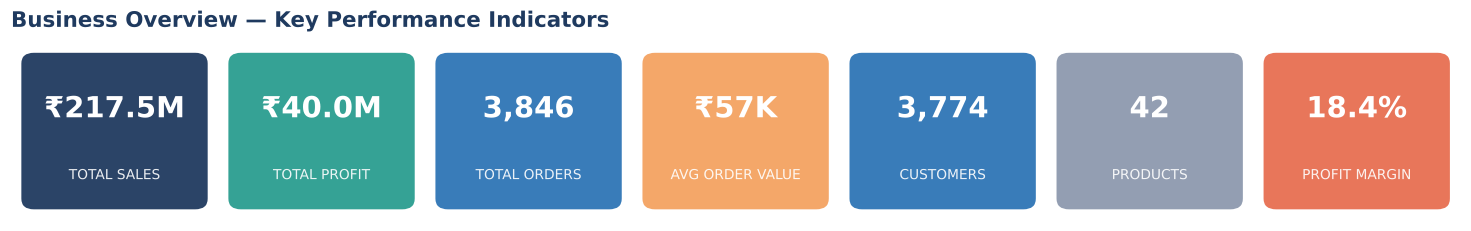

In [8]:
def draw_kpi_tiles(ax, k):
    """Draw the 7 headline KPI tiles on a given axes (reused by the one-page dashboard)."""
    tiles = [("TOTAL SALES", inr(k["Total Sales"]), NAVY), ("TOTAL PROFIT", inr(k["Total Profit"]), TEAL),
             ("TOTAL ORDERS", f"{k['Total Orders']:,.0f}", BLUE), ("AVG ORDER VALUE", inr(k["Average Order Value"]), ORANGE),
             ("CUSTOMERS", f"{k['Total Customers']:,.0f}", BLUE), ("PRODUCTS", f"{k['Total Products']:.0f}", GREY),
             ("PROFIT MARGIN", f"{k['Profit Margin (%)']:.1f}%", RED)]
    ax.set_xlim(0, len(tiles)); ax.set_ylim(0, 1); ax.axis("off")
    for i, (label, value, color) in enumerate(tiles):
        ax.add_patch(FancyBboxPatch((i + 0.05, 0.06), 0.90, 0.88, boxstyle="round,pad=0.0,rounding_size=0.06",
                                    fc=color, ec="none", alpha=0.95))
        ax.text(i + 0.5, 0.62, value, ha="center", va="center", color="white", fontsize=19, fontweight="bold")
        ax.text(i + 0.5, 0.25, label, ha="center", va="center", color="white", fontsize=9, alpha=0.9)

fig, ax = plt.subplots(figsize=(17, 2.1))
draw_kpi_tiles(ax, kpis)
ax.set_title("Business Overview — Key Performance Indicators", loc="left", fontsize=14, color=NAVY, pad=10)
save_fig(fig, "kpi_tiles")

---
# 3. Business Visualizations & Dashboard
## 3.0 Aggregations and reusable chart functions
Each chart is a small function that draws on a supplied axes. The same functions power the individual charts below **and** the one-page dashboard in section 5.

In [9]:
# ---- Aggregations (one place, reused everywhere) ---------------------------
monthly   = sales.groupby("YearMonth", as_index=False)["sales_amount"].sum()
monthly["MA3"] = monthly["sales_amount"].rolling(3).mean()
yearly    = sales.groupby("Year").agg(Sales=("sales_amount", "sum"), Profit=("profit", "sum"), Orders=("order_id", "nunique"))
yearly["Margin_%"] = yearly["Profit"] / yearly["Sales"] * 100
yearly["Sales_YoY_%"] = yearly["Sales"].pct_change() * 100

region_sales = sales.groupby("region")["sales_amount"].sum().sort_values(ascending=False)
cat = sales.groupby("product_category").agg(Sales=("sales_amount", "sum"), Profit=("profit", "sum"),
                                            Units=("quantity", "sum"), Orders=("order_id", "nunique"))
cat["Margin_%"] = cat["Profit"] / cat["Sales"] * 100
cat_by_sales = cat.sort_values("Sales", ascending=False)

cust = sales.groupby("customer_id").agg(Name=("customer_name", "first"), Sales=("sales_amount", "sum"),
                                        Orders=("order_id", "nunique"), Profit=("profit", "sum"))
top_cust = cust.nlargest(10, "Sales").copy()
top_cust["Label"] = top_cust["Name"] + " (" + top_cust.index.str[-5:] + ")"

prod = sales.groupby(["product_name", "product_category"], as_index=False).agg(
    Revenue=("sales_amount", "sum"), Units=("quantity", "sum"), Profit=("profit", "sum"))
top_prod = prod.nlargest(10, "Revenue")

age_orders = sales["Age_Group"].value_counts().reindex(["18–25", "26–35", "36–50", "51+"])
disc = sales.groupby("Discount_Band", observed=True).agg(Margin=("Profit_Margin", "mean"), Orders=("order_id", "count"))
returns = df.groupby("product_category").agg(Return_Rate=("return_flag", "mean"), Cancel_Rate=("order_status", lambda s: (s == "Cancelled").mean())) * 100

In [10]:
# ---- Reusable chart functions: every chart has a title and labelled axes ---
def plot_monthly_trend(ax, m):
    ax.plot(m["YearMonth"], m["sales_amount"], marker="o", ms=3.5, lw=1.4, color=BLUE, alpha=.75, label="Monthly sales")
    ax.plot(m["YearMonth"], m["MA3"], lw=2.6, color=ORANGE, label="3-month moving average")
    peak = m.loc[m["sales_amount"].idxmax()]
    ax.annotate(f"Peak: {peak['YearMonth']:%b %Y}\n{inr(peak['sales_amount'])}", (peak["YearMonth"], peak["sales_amount"]),
                xytext=(15, -5), textcoords="offset points", fontsize=9, color=NAVY,
                arrowprops=dict(arrowstyle="->", color=NAVY))
    ax.set(title="Monthly Sales Trend (Jan 2020 – Dec 2024)", xlabel="Month", ylabel="Sales")
    ax.yaxis.set_major_formatter(mtick.FuncFormatter(inr)); ax.set_ylim(0, m["sales_amount"].max() * 1.15)
    ax.legend(frameon=False, loc="upper left", ncol=2)

def plot_region(ax, s):
    colors = [NAVY if i == 0 else BLUE for i in range(len(s))]
    bars = ax.bar(s.index, s.values, color=colors)
    ax.bar_label(bars, labels=[inr(v) for v in s.values], padding=3, fontsize=9)
    ax.set(title="Sales by Region", xlabel="Region", ylabel="Sales"); ax.yaxis.set_major_formatter(mtick.FuncFormatter(inr))
    ax.set_ylim(0, s.max() * 1.15)

def plot_category_sales(ax, c):
    s = c["Sales"].sort_values()
    bars = ax.barh(s.index, s.values, color=[CAT_COLORS[i] for i in s.index])
    ax.bar_label(bars, labels=[inr(v) for v in s.values], padding=3, fontsize=9)
    ax.set(title="Sales by Product Category", xlabel="Sales", ylabel="Product category")
    ax.xaxis.set_major_formatter(mtick.FuncFormatter(inr)); ax.set_xlim(0, s.max() * 1.18)
    ax.xaxis.set_major_locator(mtick.MaxNLocator(4))

def plot_profit_category(ax, c):
    s = c.sort_values("Profit", ascending=False)
    bars = ax.bar(s.index, s["Profit"], color=[CAT_COLORS[i] for i in s.index])
    ax.bar_label(bars, labels=[inr(p) for p in s["Profit"]], padding=3, fontsize=9)
    ax.set_xticks(range(len(s)), [f"{n} ({m:.0f}%)" for n, m in zip(s.index, s["Margin_%"])], rotation=30, ha="right", fontsize=9)
    ax.set(title="Profit by Category (margin % in brackets)", xlabel="Product category", ylabel="Profit")
    ax.yaxis.set_major_formatter(mtick.FuncFormatter(inr)); ax.set_ylim(0, s["Profit"].max() * 1.15)

def plot_top_customers(ax, t):
    t = t.iloc[::-1]
    bars = ax.barh(t["Label"], t["Sales"], color=BLUE)
    ax.bar_label(bars, labels=[inr(v) for v in t["Sales"]], padding=3, fontsize=9)
    ax.set(title="Top 10 Customers by Sales", xlabel="Total sales", ylabel="Customer (ID suffix)")
    ax.xaxis.set_major_formatter(mtick.FuncFormatter(inr)); ax.set_xlim(0, t["Sales"].max() * 1.18)

def plot_age_pie(ax, counts):
    ax.pie(counts, labels=[f"{g}\n{v / counts.sum():.1%}" for g, v in counts.items()], startangle=90, counterclock=False,
           colors=[NAVY, BLUE, TEAL, ORANGE], wedgeprops=dict(width=0.42, edgecolor="white"), labeldistance=1.12,
           textprops=dict(fontsize=10))
    ax.set_title("Customer Segments by Age Group\n(share of orders)")

def plot_top_products(ax, t):
    t = t.iloc[::-1]
    bars = ax.barh(t["product_name"], t["Revenue"], color=[CAT_COLORS[c] for c in t["product_category"]])
    ax.bar_label(bars, labels=[inr(v) for v in t["Revenue"]], padding=3, fontsize=9)
    ax.set(title="Top 10 Products by Revenue", xlabel="Revenue", ylabel="Product")
    ax.xaxis.set_major_formatter(mtick.FuncFormatter(inr)); ax.set_xlim(0, t["Revenue"].max() * 1.18)

def plot_units_category(ax, c):
    s = c["Units"].sort_values(ascending=False)
    bars = ax.bar(s.index, s.values, color=[CAT_COLORS[i] for i in s.index])
    ax.bar_label(bars, labels=[f"{v:,.0f}" for v in s.values], padding=3, fontsize=9)
    ax.set(title="Quantity Sold by Product Category", xlabel="Product category", ylabel="Units sold")
    ax.tick_params(axis="x", rotation=25); ax.set_ylim(0, s.max() * 1.12)

def plot_discount_margin(ax, d):
    bars = ax.bar(d.index.astype(str), d["Margin"], color=[TEAL, BLUE, ORANGE, RED])
    ax.bar_label(bars, labels=[f"{v:.1f}%" for v in d["Margin"]], padding=3, fontsize=9)
    ax.set(title="Average Profit Margin by Discount Level", xlabel="Discount band", ylabel="Avg profit margin (%)")
    ax.set_ylim(0, d["Margin"].max() * 1.2)

def plot_returns(ax, r):
    s = r["Return_Rate"].sort_values(ascending=False)
    bars = ax.bar(s.index, s.values, color=RED, alpha=.85)
    ax.bar_label(bars, labels=[f"{v:.1f}%" for v in s.values], padding=3, fontsize=9)
    ax.set(title="Return Rate by Category", xlabel="Product category", ylabel="Orders returned (%)")
    ax.tick_params(axis="x", rotation=25); ax.set_ylim(0, s.max() * 1.2)

## 3.1 🏢 Business Overview

,Sales,Profit,Orders,Margin_%,Sales_YoY_%
Year,,,,,
2020,₹35.3M,₹6.4M,733,18.0%,+nan%
2021,₹43.8M,₹7.9M,769,18.0%,+24.1%
2022,₹46.4M,₹8.8M,813,18.9%,+5.9%
2023,₹43.7M,₹8.1M,773,18.6%,-5.8%
2024,₹48.4M,₹8.8M,758,18.3%,+10.8%


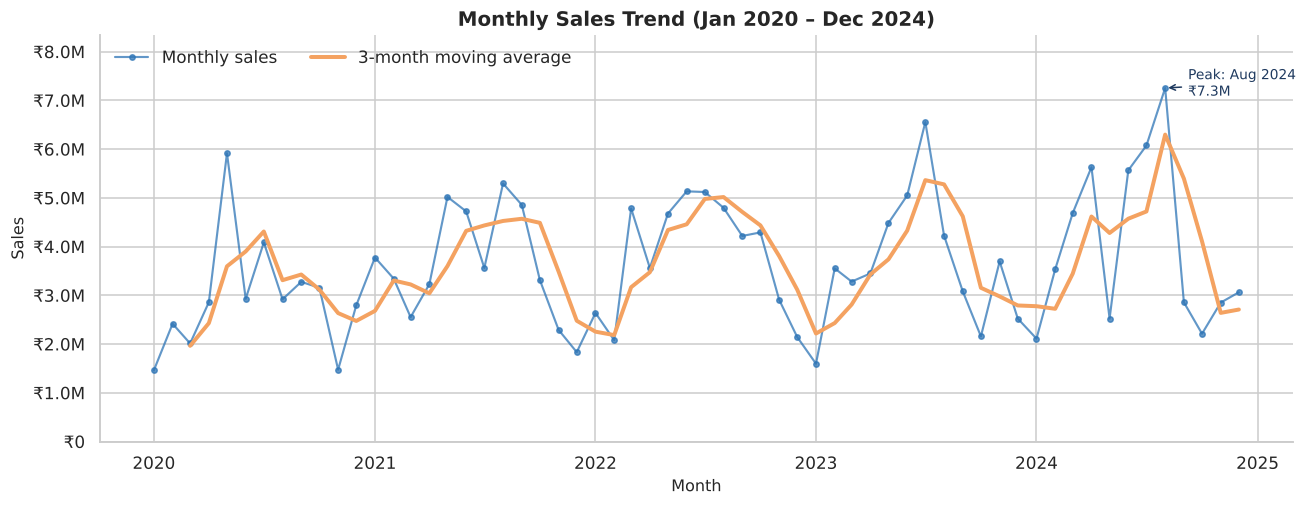

> 💡 **Takeaway:** Annual sales grew from ₹35.3M (2020) to ₹48.4M (2024), about 8.2% a year, with one down year (2023). Sales are strongly seasonal: June–August deliver 34% of the total, while January–February deliver only 12%.

In [11]:
display(yearly.style.format({"Sales": inr, "Profit": inr, "Orders": "{:,.0f}", "Margin_%": "{:.1f}%", "Sales_YoY_%": "{:+.1f}%"}))
fig, ax = plt.subplots(figsize=(14, 4.8))
plot_monthly_trend(ax, monthly)
save_fig(fig, "monthly_sales_trend")
cagr = ((yearly["Sales"].iloc[-1] / yearly["Sales"].iloc[0]) ** (1 / (len(yearly) - 1)) - 1) * 100
msum = sales.groupby("Month")["sales_amount"].sum()
takeaway(f"Annual sales grew from {inr(yearly['Sales'].iloc[0])} (2020) to {inr(yearly['Sales'].iloc[-1])} (2024), about {cagr:.1f}% a year, "
         f"with one down year (2023). Sales are strongly seasonal: June–August deliver {msum.loc[6:8].sum() / msum.sum() * 100:.0f}% of the total, "
         f"while January–February deliver only {msum.loc[1:2].sum() / msum.sum() * 100:.0f}%.")

## 3.2 💰 Sales Analysis
**Monthly trend** (above), **sales by region** and **sales by product category**.

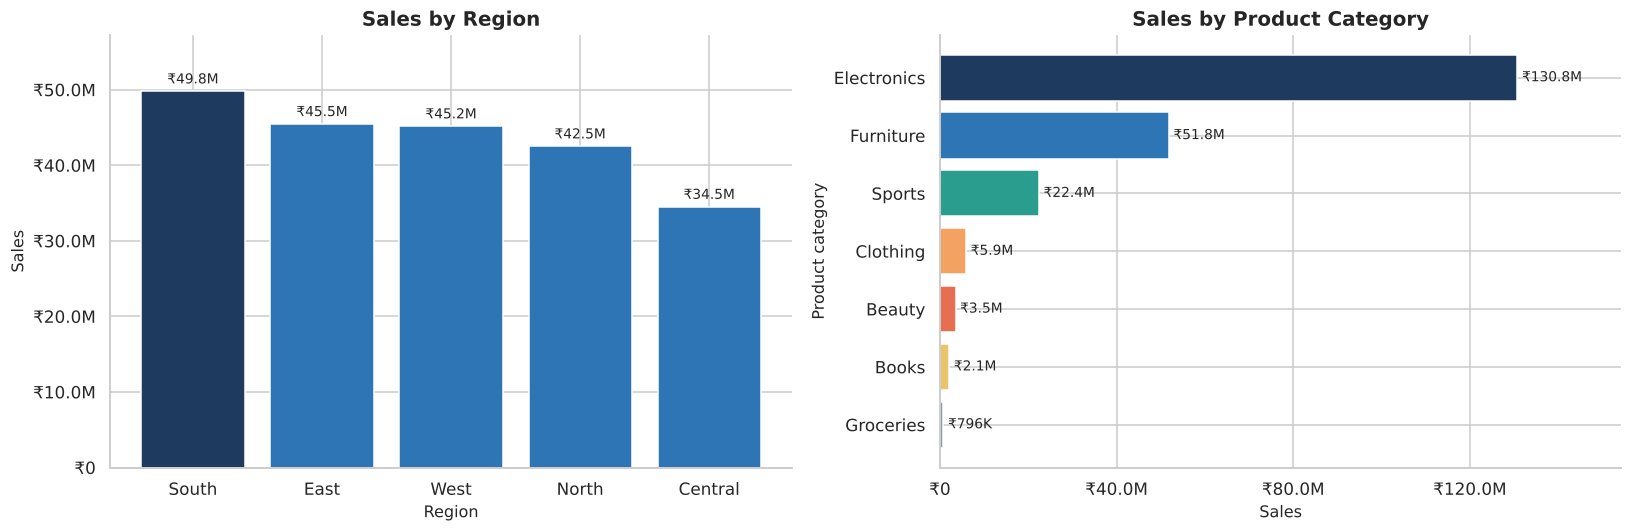

> 💡 **Takeaway:** South leads on sales (₹49.8M) and Central trails (₹34.5M). Electronics alone is 60% of revenue — the business is heavily dependent on one category.

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
plot_region(axes[0], region_sales)
plot_category_sales(axes[1], cat)
fig.tight_layout(); save_fig(fig, "sales_region_category")
takeaway(f"{region_sales.index[0]} leads on sales ({inr(region_sales.iloc[0])}) and {region_sales.index[-1]} trails ({inr(region_sales.iloc[-1])}). "
         f"Electronics alone is {cat['Sales'].max() / cat['Sales'].sum() * 100:.0f}% of revenue — the business is heavily dependent on one category.")

## 3.3 📈 Profit Analysis

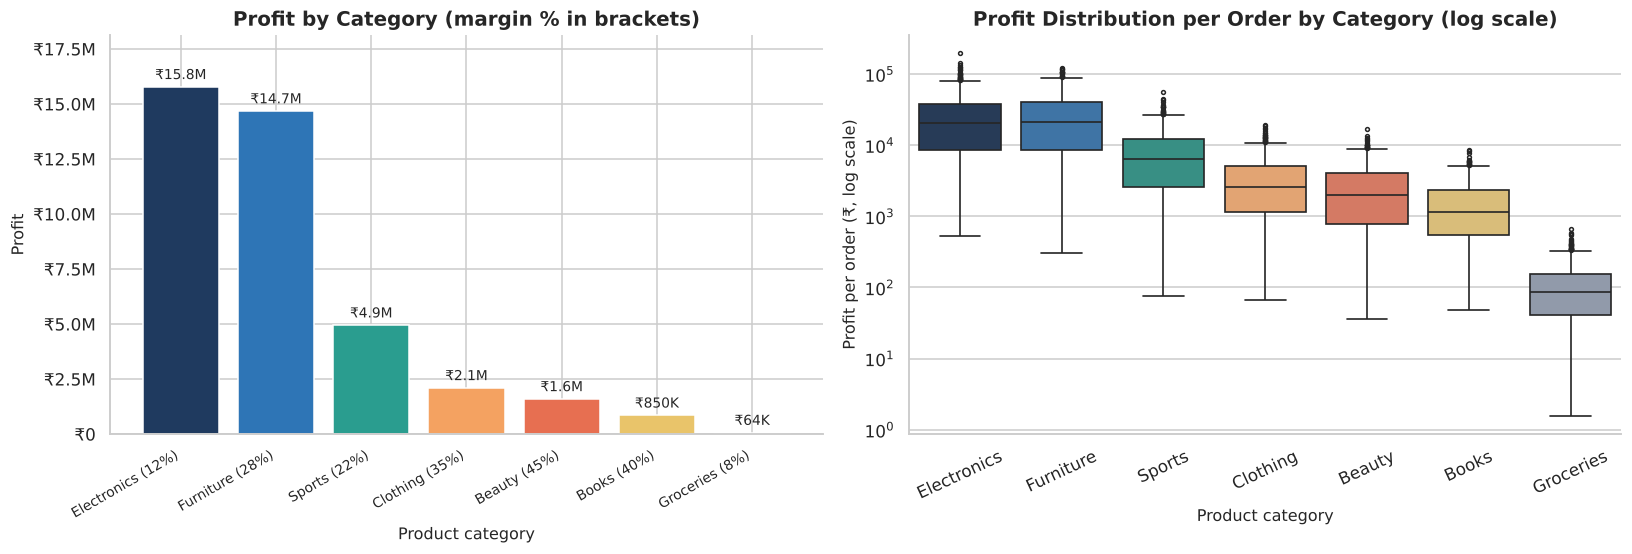

> 💡 **Takeaway:** Electronics and Furniture generate 76% of profit. Furniture earns a 28% margin versus 12% for Electronics, and per-order profit is far more variable in the high-ticket categories.

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5.2))
plot_profit_category(axes[0], cat)

order = cat.sort_values("Profit", ascending=False).index
sns.boxplot(data=sales, x="product_category", y="profit", order=order, hue="product_category", palette=CAT_COLORS,
            legend=False, ax=axes[1], fliersize=2.5, linewidth=1.1)
axes[1].set_yscale("log")
axes[1].set(title="Profit Distribution per Order by Category (log scale)", xlabel="Product category", ylabel="Profit per order (₹, log scale)")
axes[1].tick_params(axis="x", rotation=25)
fig.tight_layout(); save_fig(fig, "profit_category_boxplot")
takeaway(f"Electronics and Furniture generate {(cat.loc[['Electronics', 'Furniture'], 'Profit'].sum() / cat['Profit'].sum()) * 100:.0f}% of profit. "
         f"Furniture earns a {cat.loc['Furniture', 'Margin_%']:.0f}% margin versus {cat.loc['Electronics', 'Margin_%']:.0f}% for Electronics, "
         f"and per-order profit is far more variable in the high-ticket categories.")

*Why log scale?* Order profit ranges from about ₹2 to over ₹2 million, so a linear axis would squash every box except Electronics into a flat line.

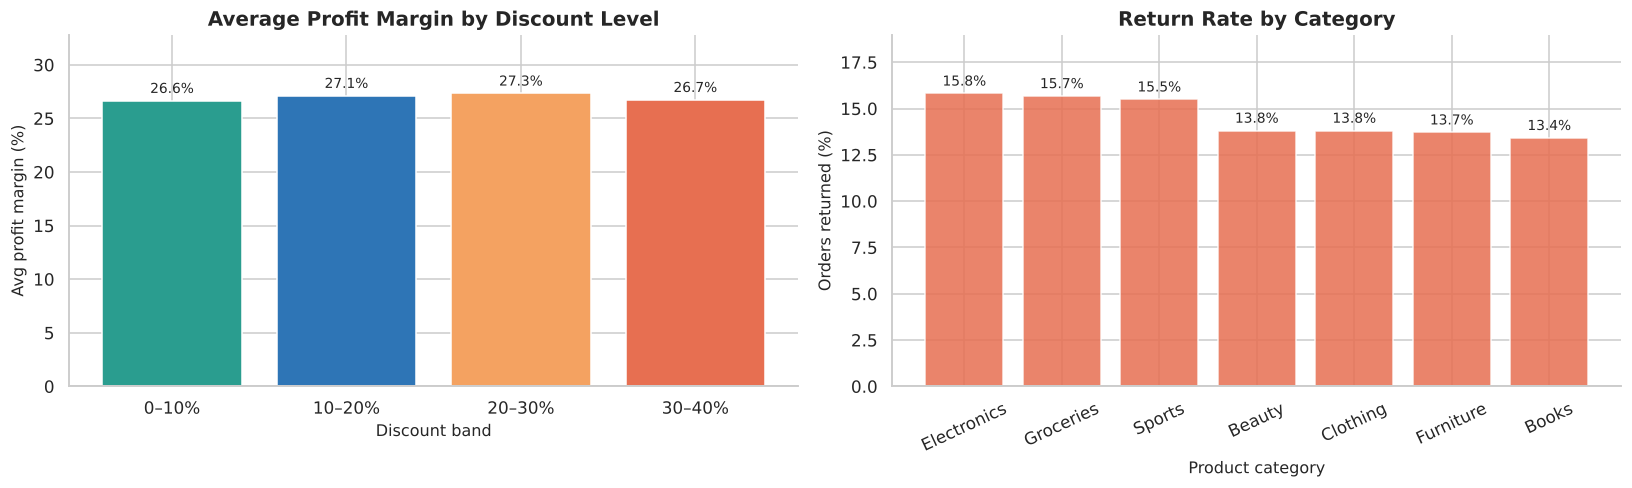

> 💡 **Takeaway:** Profit margin is flat across discount bands (26.6%–27.3%), so margin is driven by *what* is sold, not how much it is discounted. Return rates are high everywhere (13.4%–15.8%) — a business-wide issue, not one category.

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.6))
plot_discount_margin(axes[0], disc)
plot_returns(axes[1], returns)
fig.tight_layout(); save_fig(fig, "profit_drivers")
takeaway(f"Profit margin is flat across discount bands ({disc['Margin'].min():.1f}%–{disc['Margin'].max():.1f}%), so margin is driven by *what* is sold, not how much it is discounted. "
         f"Return rates are high everywhere ({returns['Return_Rate'].min():.1f}%–{returns['Return_Rate'].max():.1f}%) — a business-wide issue, not one category.")

## 3.4 👥 Customer Analysis

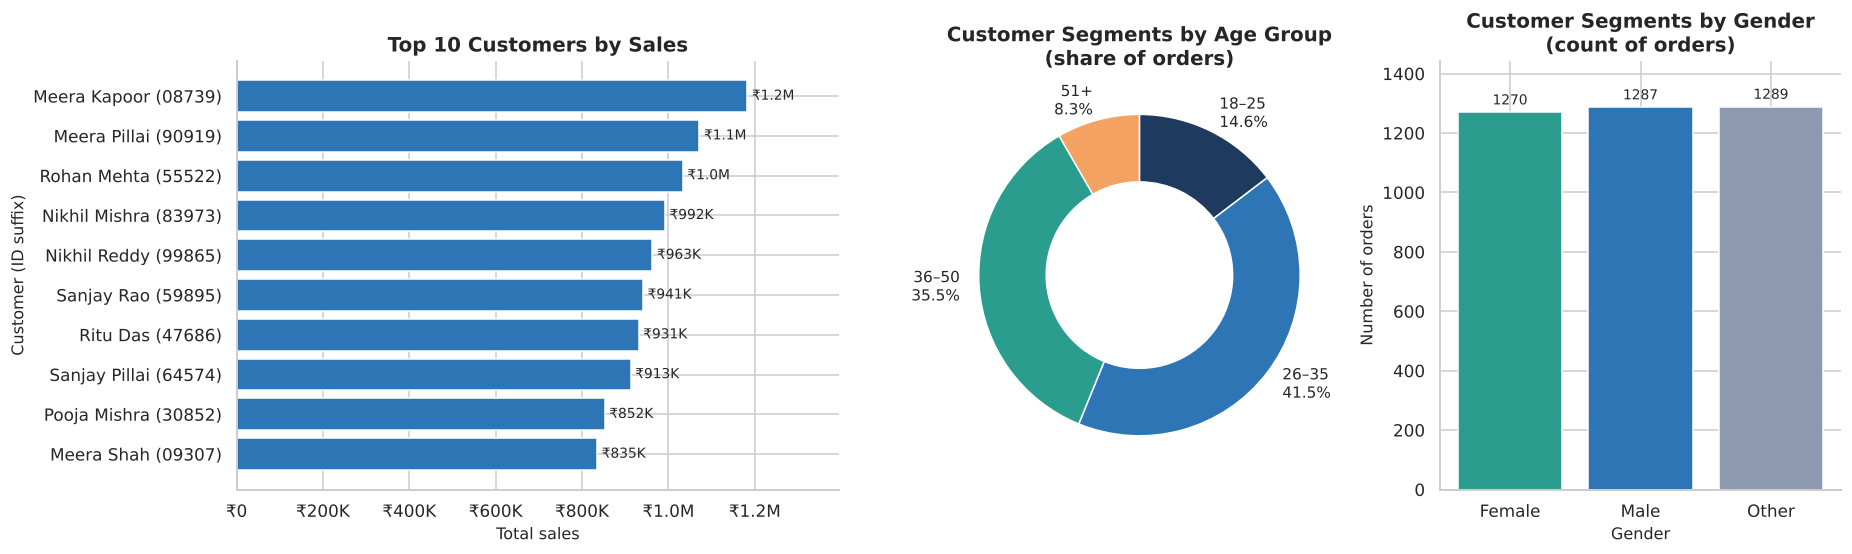

Top-10 customers contribute 4.5% of sales. Only 1.9% of customers ordered more than once.
Note: ~11% of ages were missing/impossible and were median-imputed, which slightly inflates the 26–35 segment.


In [15]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5.2), gridspec_kw={"width_ratios": [1.5, 1, 1]})
plot_top_customers(axes[0], top_cust)
plot_age_pie(axes[1], age_orders)
gender_orders = sales["gender"].value_counts().reindex(["Female", "Male", "Other"])        # count plot of orders per gender
bars = axes[2].bar(gender_orders.index, gender_orders.values, color=[TEAL, BLUE, GREY])
axes[2].bar_label(bars, padding=3, fontsize=9); axes[2].set_ylim(0, gender_orders.max() * 1.12)
axes[2].set(title="Customer Segments by Gender\n(count of orders)", xlabel="Gender", ylabel="Number of orders")
fig.tight_layout(); save_fig(fig, "customer_analysis")

top10_share = top_cust["Sales"].sum() / sales["sales_amount"].sum() * 100
repeat_pct = (cust["Orders"] > 1).mean() * 100
print(f"Top-10 customers contribute {top10_share:.1f}% of sales. Only {repeat_pct:.1f}% of customers ordered more than once.")
print("Note: ~11% of ages were missing/impossible and were median-imputed, which slightly inflates the 26–35 segment.")

## 3.5 📦 Product Performance

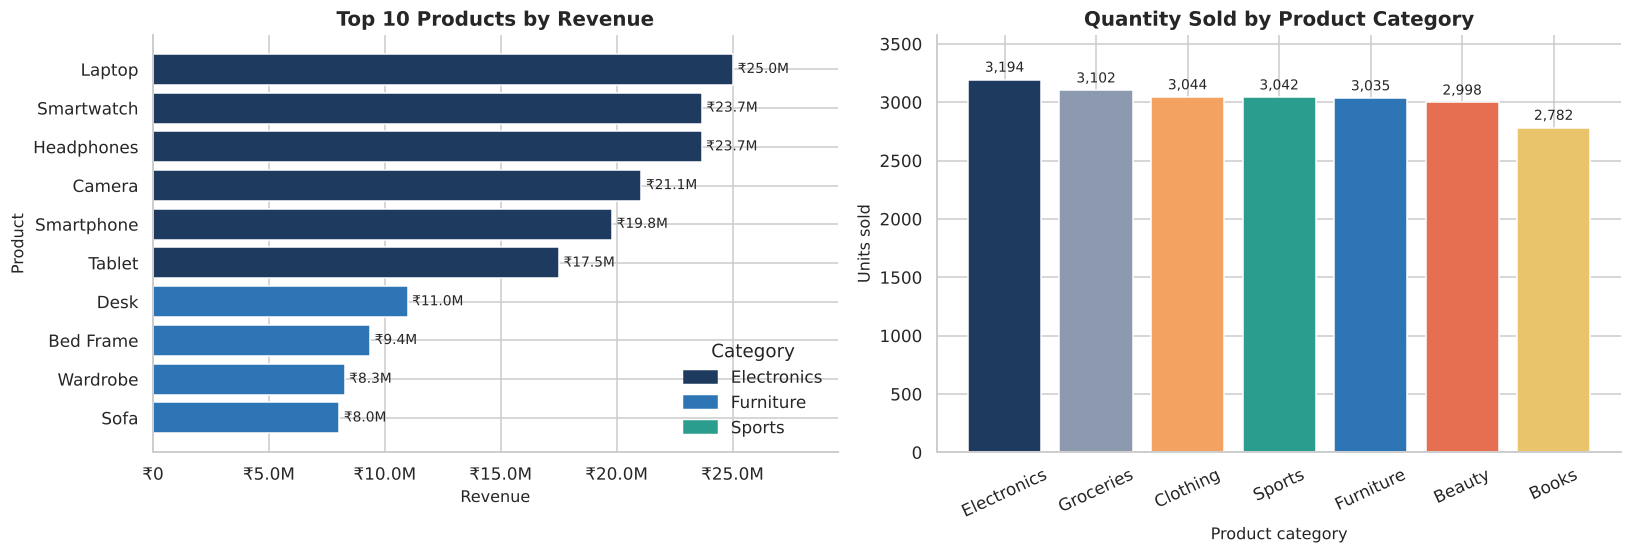

> 💡 **Takeaway:** The top 6 products by revenue are all Electronics. Yet units sold are nearly equal across categories (2,782–3,194), so the revenue gap comes from **price per unit, not volume**.

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5.2))
plot_top_products(axes[0], top_prod)
plot_units_category(axes[1], cat)
handles = [plt.Rectangle((0, 0), 1, 1, color=CAT_COLORS[c]) for c in ["Electronics", "Furniture", "Sports"]]
axes[0].legend(handles, ["Electronics", "Furniture", "Sports"], title="Category", frameon=False, loc="lower right")
fig.tight_layout(); save_fig(fig, "product_performance")
takeaway(f"The top {int((top_prod['product_category'] == 'Electronics').sum())} products by revenue are all Electronics. Yet units sold are nearly equal across categories "
         f"({cat['Units'].min():,.0f}–{cat['Units'].max():,.0f}), so the revenue gap comes from **price per unit, not volume**.")

---
# 4. Advanced Visualizations
Four advanced charts: **correlation heatmap**, **scatter plots with regression lines**, **violin plot**, and **distribution plots (histogram + KDE)**.

## 4.1 Correlation heatmap

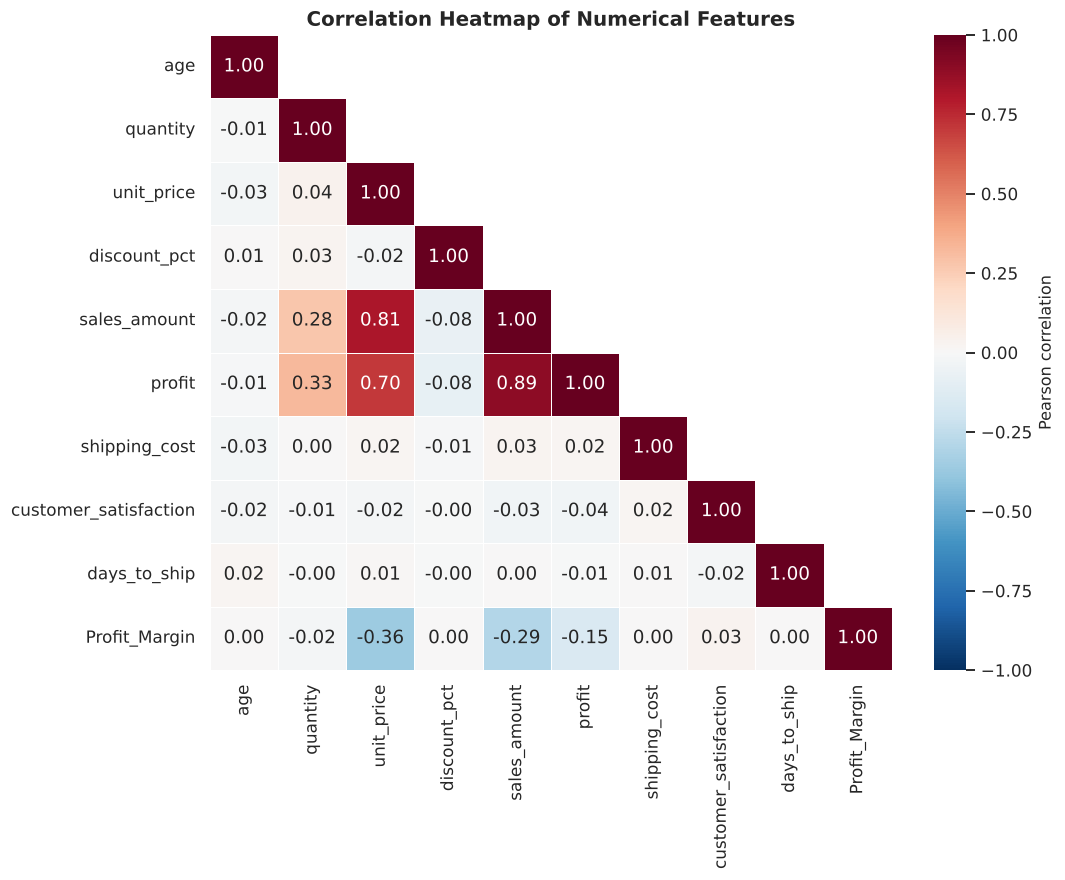

> 💡 **Takeaway:** Profit follows sales and unit price closely, but **profit margin falls as unit price rises (negative correlation)** — expensive items earn a thinner percentage. Shipping time, discount and satisfaction show almost no linear relationship with the other metrics.

sales ↔ profit: 0.89 | discount ↔ margin: 0.00 | unit price ↔ margin: -0.36 | days to ship ↔ satisfaction: -0.02


In [17]:
num_cols = ["age", "quantity", "unit_price", "discount_pct", "sales_amount", "profit", "shipping_cost",
            "customer_satisfaction", "days_to_ship", "Profit_Margin"]
corr = sales[num_cols].corr()
fig, ax = plt.subplots(figsize=(10, 7.5))
sns.heatmap(corr, mask=np.triu(np.ones_like(corr, dtype=bool), k=1), annot=True, fmt=".2f", cmap="RdBu_r", center=0,
            vmin=-1, vmax=1, linewidths=.5, cbar_kws={"label": "Pearson correlation"}, ax=ax)
ax.set_title("Correlation Heatmap of Numerical Features"); ax.grid(False)
save_fig(fig, "correlation_heatmap")
takeaway("Profit follows sales and unit price closely, but **profit margin falls as unit price rises (negative correlation)** — expensive items earn a thinner percentage. "
         "Shipping time, discount and satisfaction show almost no linear relationship with the other metrics.")
print(f"sales ↔ profit: {corr.loc['sales_amount','profit']:.2f} | discount ↔ margin: {corr.loc['discount_pct','Profit_Margin']:.2f} | "
      f"unit price ↔ margin: {corr.loc['unit_price','Profit_Margin']:.2f} | days to ship ↔ satisfaction: {corr.loc['days_to_ship','customer_satisfaction']:.2f}")

## 4.2 Scatter plots with regression lines

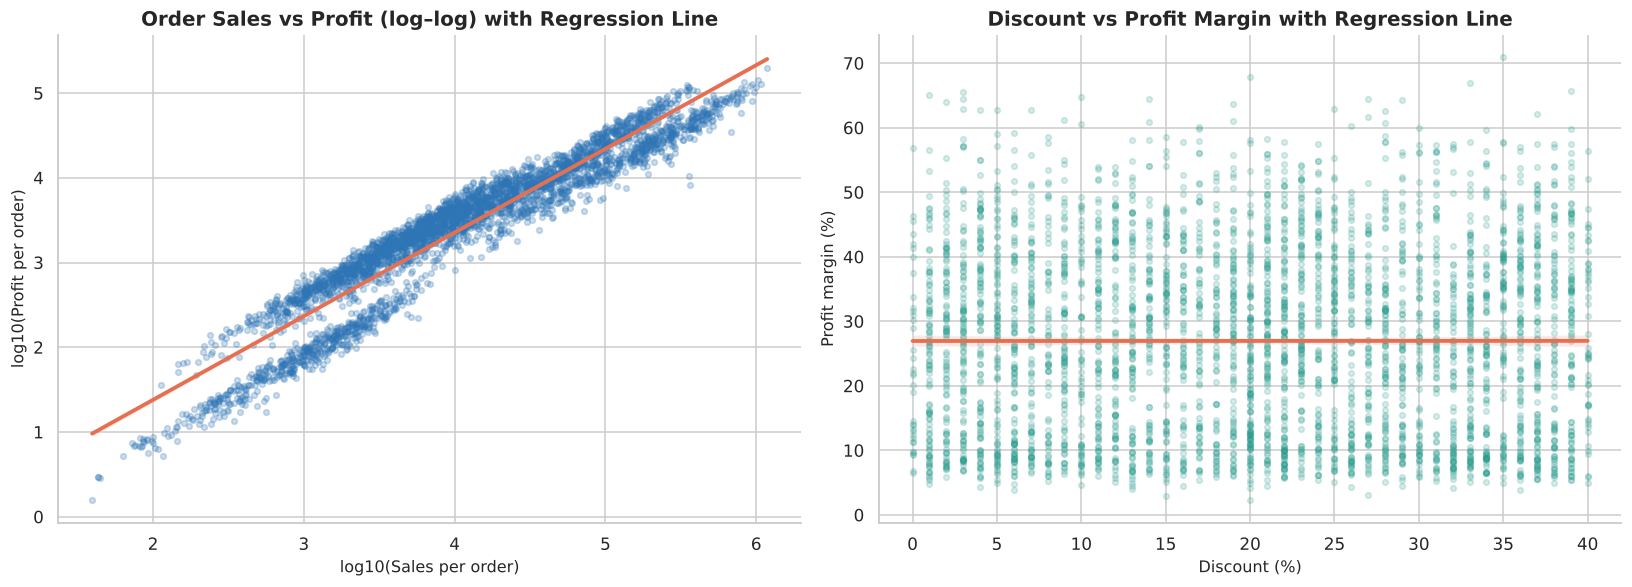

Regression slope: each extra 1 pp of discount changes profit margin by +0.001 pp -> effectively zero.


In [18]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
sns.regplot(x=np.log10(sales["sales_amount"]), y=np.log10(sales["profit"]), scatter_kws=dict(alpha=.25, s=14, color=BLUE),
            line_kws=dict(color=RED, lw=2.5), ax=axes[0])
axes[0].set(title="Order Sales vs Profit (log–log) with Regression Line", xlabel="log10(Sales per order)", ylabel="log10(Profit per order)")

sns.regplot(x=sales["discount_pct"] * 100, y=sales["Profit_Margin"], scatter_kws=dict(alpha=.2, s=14, color=TEAL),
            line_kws=dict(color=RED, lw=2.5), ax=axes[1])
axes[1].set(title="Discount vs Profit Margin with Regression Line", xlabel="Discount (%)", ylabel="Profit margin (%)")
fig.tight_layout(); save_fig(fig, "scatter_regression")

slope = np.polyfit(sales["discount_pct"] * 100, sales["Profit_Margin"], 1)[0]
print(f"Regression slope: each extra 1 pp of discount changes profit margin by {slope:+.3f} pp -> effectively zero.")

## 4.3 Violin plot — profit-margin spread by category

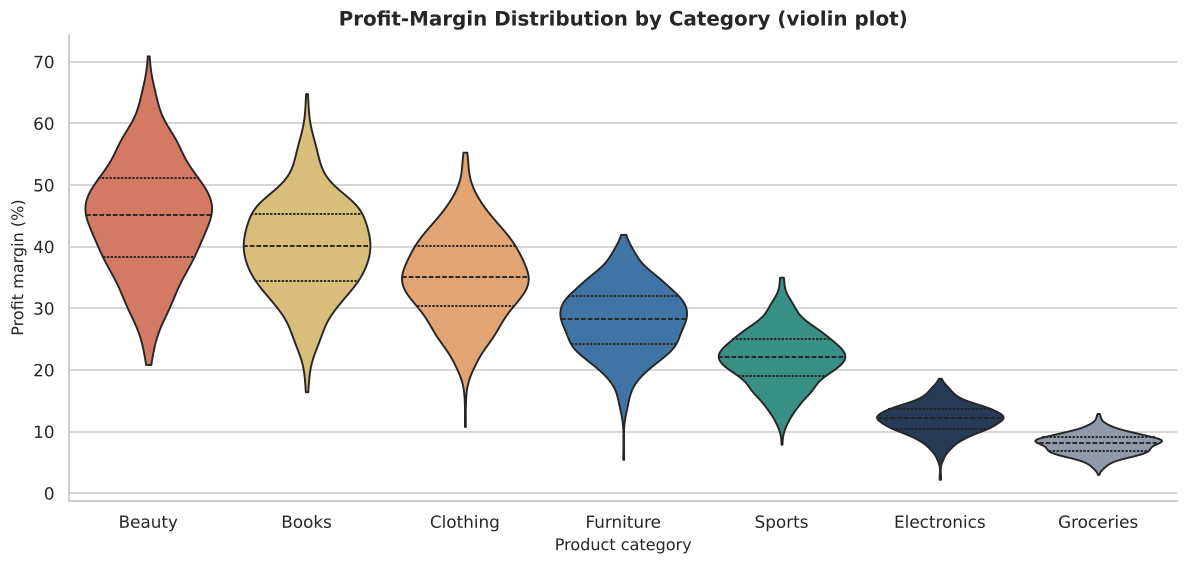

In [19]:
order_m = sales.groupby("product_category")["Profit_Margin"].median().sort_values(ascending=False).index
fig, ax = plt.subplots(figsize=(13, 5.5))
sns.violinplot(data=sales, x="product_category", y="Profit_Margin", order=order_m, hue="product_category",
               palette=CAT_COLORS, legend=False, inner="quartile", cut=0, ax=ax)
ax.set(title="Profit-Margin Distribution by Category (violin plot)", xlabel="Product category", ylabel="Profit margin (%)")
save_fig(fig, "violin_margin")

## 4.4 Distribution plots (histogram + KDE)

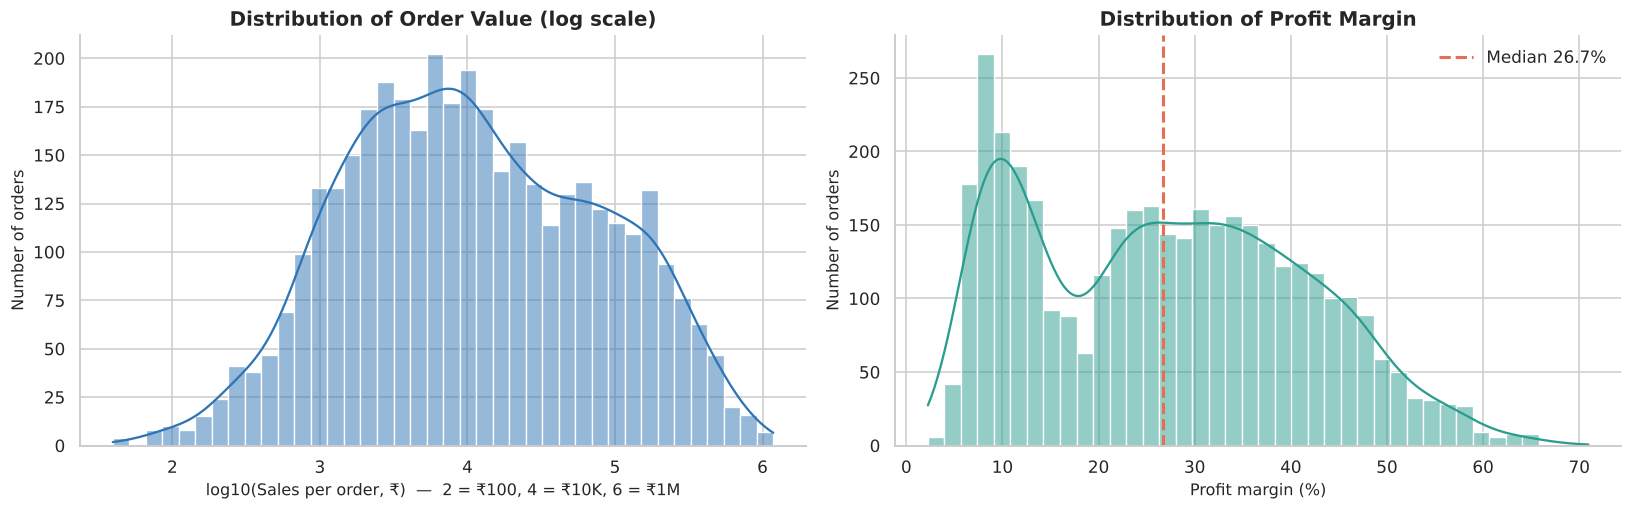

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))
sns.histplot(np.log10(sales["sales_amount"]), bins=40, kde=True, color=BLUE, ax=axes[0])
axes[0].set(title="Distribution of Order Value (log scale)", xlabel="log10(Sales per order, ₹)  —  2 = ₹100, 4 = ₹10K, 6 = ₹1M", ylabel="Number of orders")
sns.histplot(sales["Profit_Margin"], bins=40, kde=True, color=TEAL, ax=axes[1])
axes[1].axvline(sales["Profit_Margin"].median(), color=RED, ls="--", lw=2, label=f"Median {sales['Profit_Margin'].median():.1f}%")
axes[1].set(title="Distribution of Profit Margin", xlabel="Profit margin (%)", ylabel="Number of orders"); axes[1].legend(frameon=False)
fig.tight_layout(); save_fig(fig, "distributions")

---
# 5. One-Page Analytical Dashboard
All five dashboard areas — **Business Overview, Sales, Customers, Products, Profit** — consolidated into one figure (also saved as `figures/dashboard_overview.png`).

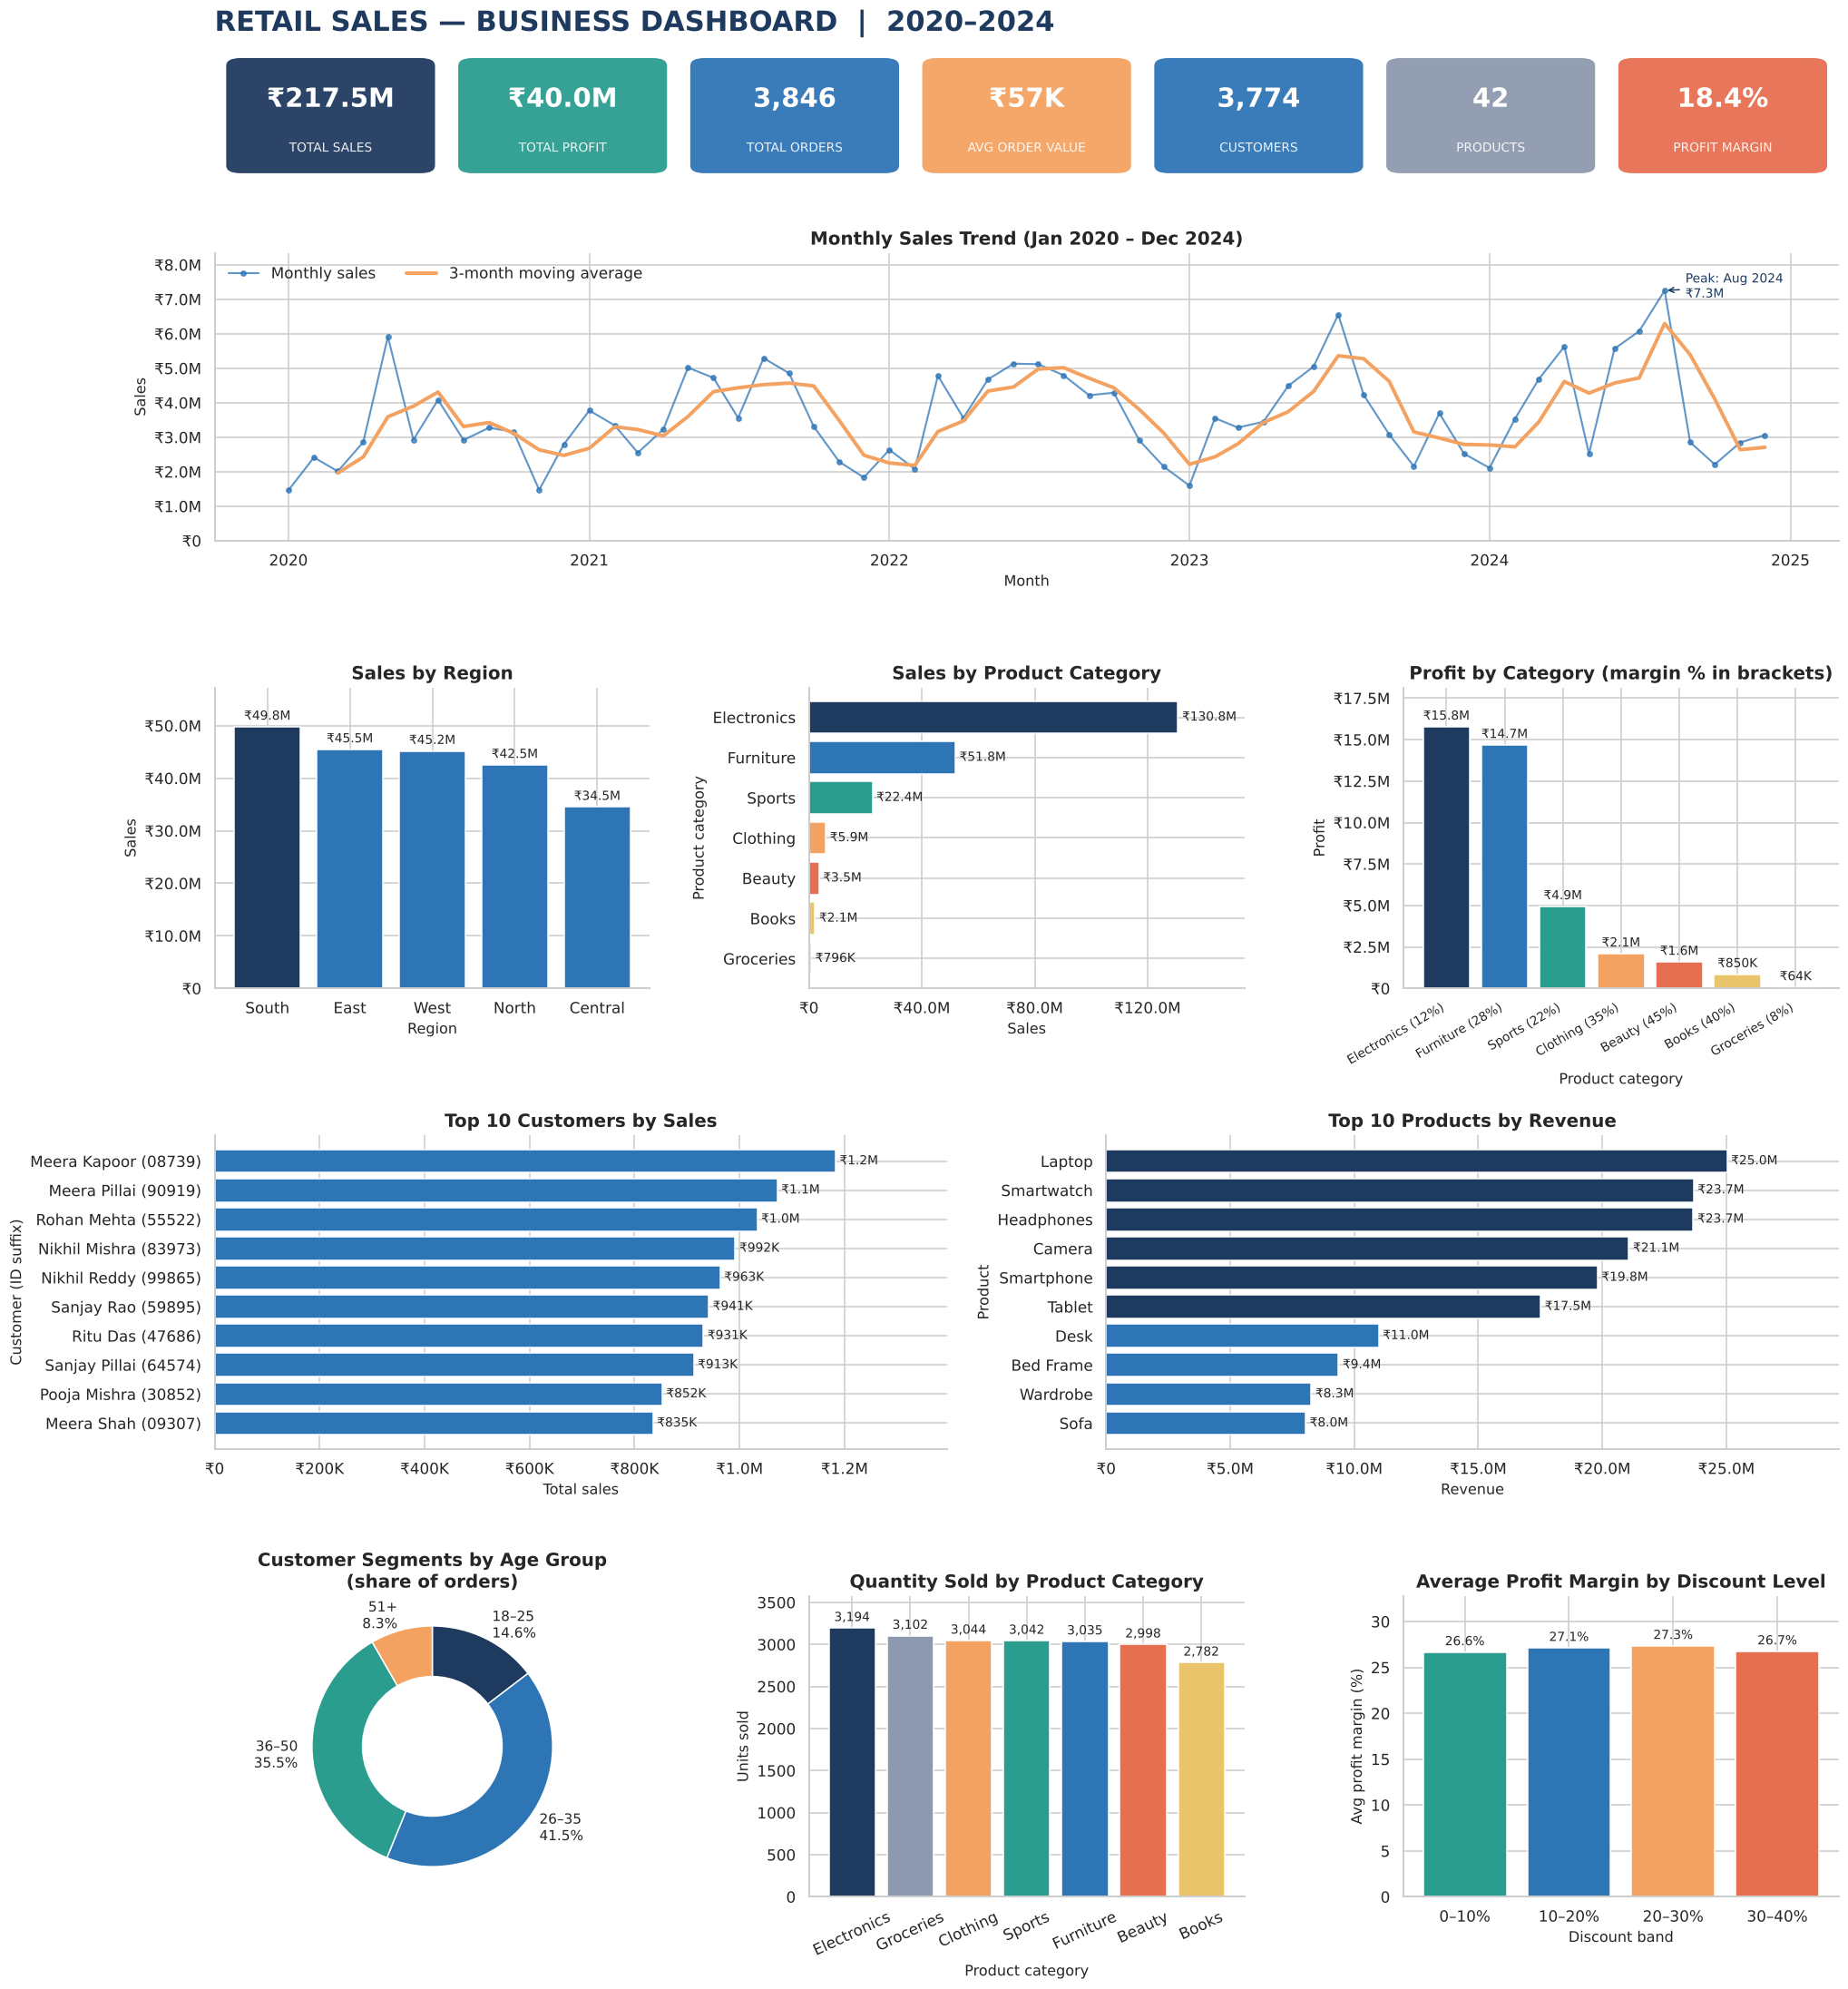

In [21]:
fig = plt.figure(figsize=(21, 25), facecolor="white")
gs = GridSpec(5, 6, figure=fig, height_ratios=[0.5, 1.1, 1.15, 1.2, 1.15], hspace=0.55, wspace=1.15)

ax = fig.add_subplot(gs[0, :]); draw_kpi_tiles(ax, kpis)
pos = ax.get_position(); ax.set_position([pos.x0, pos.y0 - 0.03, pos.width, pos.height])   # tighten gap under the KPI row
ax.set_title("RETAIL SALES — BUSINESS DASHBOARD  |  2020–2024", loc="left", fontsize=20, color=NAVY, fontweight="bold", pad=14)

plot_monthly_trend(fig.add_subplot(gs[1, :]), monthly)                                   # Business overview
plot_region(fig.add_subplot(gs[2, 0:2]), region_sales)                                   # Sales
plot_category_sales(fig.add_subplot(gs[2, 2:4]), cat)
plot_profit_category(fig.add_subplot(gs[2, 4:6]), cat)                                   # Profit
plot_top_customers(fig.add_subplot(gs[3, 0:3]), top_cust)                                # Customers
plot_top_products(fig.add_subplot(gs[3, 3:6]), top_prod)                                 # Products
plot_age_pie(fig.add_subplot(gs[4, 0:2]), age_orders)                                    # Customers
plot_units_category(fig.add_subplot(gs[4, 2:4]), cat)                                    # Products
plot_discount_margin(fig.add_subplot(gs[4, 4:6]), disc)                                  # Profit
save_fig(fig, "dashboard_overview")

---
# 6. Business Insights Report
## 6.1 Executive Summary & Key Findings
*(All numbers below are computed live from the data.)*

In [22]:
best_region, best_region_sales = region_sales.index[0], region_sales.iloc[0]
region_share = best_region_sales / region_sales.sum() * 100
top_cat, top_cat_sales = cat_by_sales.index[0], cat_by_sales["Sales"].iloc[0]
cat_share = top_cat_sales / cat["Sales"].sum() * 100
profit_leader = cat["Profit"].idxmax(); margin_leader = cat["Margin_%"].idxmax(); margin_laggard = cat["Margin_%"].idxmin()
peak_m = monthly.loc[monthly["sales_amount"].idxmax()]; low_m = monthly.loc[monthly["sales_amount"].idxmin()]
season = sales.groupby("Month")["sales_amount"].mean()
best_cal, worst_cal = season.idxmax(), season.idxmin()
mname = lambda m: pd.Timestamp(2000, int(m), 1).strftime("%B")
units_top = prod.nlargest(5, "Units")
disc_gap = disc["Margin"].iloc[0] - disc["Margin"].iloc[-1]

summary = f"""
| Finding | Result |
|---|---|
| 🏆 **Best-performing region** | **{best_region}** — {inr(best_region_sales)} ({region_share:.1f}% of sales); weakest is **{region_sales.index[-1]}** at {inr(region_sales.iloc[-1])} |
| 💎 **Highest-revenue category** | **{top_cat}** — {inr(top_cat_sales)} ({cat_share:.1f}% of sales) but only a {cat.loc[top_cat,'Margin_%']:.1f}% margin |
| 💰 **Most profitable category** | **{profit_leader}** ({inr(cat.loc[profit_leader,'Profit'])}); best margin is **{margin_leader}** ({cat.loc[margin_leader,'Margin_%']:.1f}%), worst is **{margin_laggard}** ({cat.loc[margin_laggard,'Margin_%']:.1f}%) |
| 🛒 **Best-selling products (revenue)** | {', '.join(f"{r.product_name} ({inr(r.Revenue)})" for r in top_prod.head(5).itertuples())} |
| 📦 **Best-selling products (units)** | {', '.join(f"{r.product_name} ({r.Units:,.0f})" for r in units_top.itertuples())} |
| 👑 **Highest-value customers** | {', '.join(f"{r.Name} ({inr(r.Sales)})" for r in top_cust.head(3).itertuples())} … top 10 = {top10_share:.1f}% of sales |
| 📅 **Monthly trend** | Peak **{peak_m['YearMonth']:%b %Y}** ({inr(peak_m['sales_amount'])}); low **{low_m['YearMonth']:%b %Y}** ({inr(low_m['sales_amount'])}); on average **{mname(best_cal)}** is strongest and **{mname(worst_cal)}** weakest |
| 📉 **Year-over-year** | {' · '.join(f"{y}: {inr(r.Sales)} ({r['Sales_YoY_%']:+.0f}%)" if y > yearly.index.min() else f"{y}: {inr(r.Sales)}" for y, r in yearly.iterrows())} |
| ⚠️ **Risk metrics** | Return rate **{kpis['Return Rate (%)']:.1f}%**, cancellation rate **{kpis['Cancellation Rate (%)']:.1f}%**, avg satisfaction **{kpis['Avg Satisfaction (1-5)']:.2f}/5** |
"""
display(Markdown(summary))


| Finding | Result |
|---|---|
| 🏆 **Best-performing region** | **South** — ₹49.8M (22.9% of sales); weakest is **Central** at ₹34.5M |
| 💎 **Highest-revenue category** | **Electronics** — ₹130.8M (60.1% of sales) but only a 12.1% margin |
| 💰 **Most profitable category** | **Electronics** (₹15.8M); best margin is **Beauty** (45.1%), worst is **Groceries** (8.0%) |
| 🛒 **Best-selling products (revenue)** | Laptop (₹25.0M), Smartwatch (₹23.7M), Headphones (₹23.7M), Camera (₹21.1M), Smartphone (₹19.8M) |
| 📦 **Best-selling products (units)** | Desk (627), Textbook (615), Laptop (610), Smartwatch (605), Face Cream (599) |
| 👑 **Highest-value customers** | Meera Kapoor (₹1.2M), Meera Pillai (₹1.1M), Rohan Mehta (₹1.0M) … top 10 = 4.5% of sales |
| 📅 **Monthly trend** | Peak **Aug 2024** (₹7.3M); low **Jan 2020** (₹1.5M); on average **June** is strongest and **January** weakest |
| 📉 **Year-over-year** | 2020: ₹35.3M · 2021: ₹43.8M (+24%) · 2022: ₹46.4M (+6%) · 2023: ₹43.7M (-6%) · 2024: ₹48.4M (+11%) |
| ⚠️ **Risk metrics** | Return rate **14.6%**, cancellation rate **8.3%**, avg satisfaction **3.02/5** |


## 6.2 Supporting diagnostics for the recommendations

In [23]:
diag = pd.DataFrame({
    "Sales share %": cat["Sales"] / cat["Sales"].sum() * 100,
    "Profit share %": cat["Profit"] / cat["Profit"].sum() * 100,
    "Margin %": cat["Margin_%"],
    "Return rate %": returns["Return_Rate"],
    "Cancel rate %": returns["Cancel_Rate"],
    "Avg satisfaction": df.groupby("product_category")["customer_satisfaction"].mean(),
}).sort_values("Sales share %", ascending=False)
display(diag.style.format("{:.1f}").format({"Avg satisfaction": "{:.2f}"}))

ship_sat = df.groupby(pd.cut(df["days_to_ship"], [-1, 3, 6, 9, 30], labels=["0–3 d", "4–6 d", "7–9 d", "10+ d"]), observed=True).agg(
    Satisfaction=("customer_satisfaction", "mean"), Return_Rate=("return_flag", "mean"), Orders=("order_id", "count"))
ship_sat["Return_Rate"] *= 100
display(ship_sat.style.format({"Satisfaction": "{:.2f}", "Return_Rate": "{:.1f}%"}))
pay = df.groupby("payment_method").agg(Return_Rate=("return_flag", "mean"), Cancel_Rate=("order_status", lambda s: (s == "Cancelled").mean())) * 100
display(pay.sort_values("Cancel_Rate", ascending=False).style.format("{:.1f}%"))
reg_m = sales.groupby("region").agg(Sales=("sales_amount", "sum"), Profit=("profit", "sum")); reg_m["Margin_%"] = reg_m["Profit"] / reg_m["Sales"] * 100
display(reg_m.sort_values("Sales", ascending=False).style.format({"Sales": inr, "Profit": inr, "Margin_%": "{:.1f}%"}))

,Sales share %,Profit share %,Margin %,Return rate %,Cancel rate %,Avg satisfaction
product_category,,,,,,
Electronics,60.134003,39.441952,12.063906,15.815486,7.413509,3.00
Furniture,23.843466,36.686884,28.300304,13.715278,9.201389,3.03
Sports,10.319301,12.360461,22.030993,15.497553,6.362153,2.91
Clothing,2.732656,5.239920,35.268688,13.809524,9.682540,3.06
Beauty,1.626556,3.985648,45.069160,13.810316,7.487521,3.04
Books,0.977882,2.126148,39.990486,13.416816,9.481216,3.11
Groceries,0.366136,0.158988,7.986783,15.676568,8.250825,2.98


,Satisfaction,Return_Rate,Orders
days_to_ship,,,
0–3 d,3.02,14.6%,1222
4–6 d,3.03,13.3%,1325
7–9 d,3.02,15.1%,1251
10+ d,2.96,16.8%,394


,Return_Rate,Cancel_Rate
payment_method,,
Debit Card,15.3%,10.1%
EMI,14.7%,8.2%
Net Banking,13.6%,7.9%
Cash on Delivery,12.9%,7.8%
Credit Card,15.8%,7.8%
UPI,14.8%,7.7%


,Sales,Profit,Margin_%
region,,,
South,₹49.8M,₹9.0M,18.1%
East,₹45.5M,₹8.0M,17.6%
West,₹45.2M,₹8.3M,18.5%
North,₹42.5M,₹8.0M,18.7%
Central,₹34.5M,₹6.7M,19.3%


## 6.3 Business Recommendations
Seven recommendations, each tied to evidence computed from this dataset.

In [24]:
n_cust, aov = len(cust), kpis["Average Order Value"]
elec, furn = cat.loc["Electronics"], cat.loc["Furniture"]
hi_m = cat.loc[["Beauty", "Books", "Clothing"]]
msum = sales.groupby("Month")["sales_amount"].sum()
peak_share, low_share = msum.loc[6:8].sum() / msum.sum() * 100, msum.loc[1:2].sum() / msum.sum() * 100
aov_band = sales.groupby("Discount_Band", observed=True)["sales_amount"].mean()
units_band = sales.groupby("Discount_Band", observed=True)["quantity"].mean()
returned = df[df["return_flag"]]
sat_ret, sat_ok = df.loc[df.return_flag, "customer_satisfaction"].mean(), df.loc[~df.return_flag, "customer_satisfaction"].mean()
cancel_pay = (df.groupby("payment_method")["order_status"].apply(lambda s: (s == "Cancelled").mean()) * 100).sort_values(ascending=False)
reg_m = sales.groupby("region").agg(Sales=("sales_amount", "sum"), Profit=("profit", "sum"))
reg_m["Margin"] = reg_m["Profit"] / reg_m["Sales"] * 100
city_sales = sales.groupby("city")["sales_amount"].sum().sort_values()
weak_reg = region_sales.index[-1]
repeat_now = repeat_pct
extra_orders = (0.05 - repeat_now / 100) * n_cust
ret_pp_value = returned["sales_amount"].sum() / kpis["Return Rate (%)"]

recs = [
 dict(title="Raise Electronics margin — it is 60% of revenue but earns only 12%",
      evidence=f"Electronics = {elec['Sales'] / cat['Sales'].sum() * 100:.0f}% of sales but a {elec['Margin_%']:.1f}% margin (Furniture earns {furn['Margin_%']:.1f}%). Margin also falls as unit price rises (r = {corr.loc['unit_price', 'Profit_Margin']:.2f}).",
      action=f"Renegotiate supplier costs and sell higher-margin accessories/warranties with devices. Each +1 pp of Electronics margin adds about {inr(elec['Sales'] * 0.01)} profit; +2 pp ≈ {inr(elec['Sales'] * 0.02)}."),
 dict(title="Cross-sell and grow the high-margin categories",
      evidence=f"Beauty, Books and Clothing earn {hi_m['Margin_%'].min():.0f}–{hi_m['Margin_%'].max():.0f}% margins (every ₹100 of Beauty sales keeps ₹{cat.loc['Beauty', 'Margin_%']:.0f} vs ₹{elec['Margin_%']:.0f} for Electronics) yet are only {hi_m['Sales'].sum() / cat['Sales'].sum() * 100:.0f}% of sales. Furniture gives {furn['Profit'] / cat['Profit'].sum() * 100:.0f}% of profit from {furn['Sales'] / cat['Sales'].sum() * 100:.0f}% of sales.",
      action="Bundle Beauty/Clothing/Books offers into Electronics checkouts and email campaigns; give Furniture more marketing weight than its sales share suggests."),
 dict(title="Build a customer-retention programme — almost nobody comes back",
      evidence=f"Only {repeat_now:.1f}% of {n_cust:,} customers ordered more than once, and the top-10 customers are just {top10_share:.1f}% of sales: growth depends on constantly acquiring new buyers.",
      action=f"Launch loyalty points, post-purchase follow-ups and replenishment reminders (Groceries, Beauty). Illustration: lifting repeat customers to 5% adds ≈{extra_orders:,.0f} orders ≈ {inr(extra_orders * aov)} revenue at the current {inr(aov)} order value."),
 dict(title="Plan stock, staffing and campaigns around seasonality",
      evidence=f"June–August bring {peak_share:.0f}% of annual sales; January–February only {low_share:.0f}%. Peak month: {peak_m['YearMonth']:%b %Y} ({inr(peak_m['sales_amount'])}).",
      action="Pre-build inventory and logistics capacity before May, and run off-season promotions (Nov–Feb), focused on non-Electronics categories, to smooth the revenue curve."),
 dict(title="Cut returns and cancellations — they erode revenue and satisfaction",
      evidence=f"{kpis['Return Rate (%)']:.1f}% of orders are returned ({inr(returned['sales_amount'].sum())} of sales, {returned['sales_amount'].sum() / sales['sales_amount'].sum() * 100:.0f}% of the total). Returners rate their experience {sat_ret:.2f}/5 vs {sat_ok:.2f}/5. {cancel_pay.index[0]} orders cancel most ({cancel_pay.iloc[0]:.1f}% vs {cancel_pay.iloc[1:].mean():.1f}% for other methods).",
      action=f"Capture a return reason on every return, improve product descriptions/size guides, and audit the {cancel_pay.index[0]} payment flow. Each 1 pp reduction in return rate protects ≈ {inr(ret_pp_value)} of sales."),
 dict(title="Cap deep discounts — they shrink order value without lifting volume",
      evidence=f"Orders with 30–40% discounts average {inr(aov_band.iloc[-1])} vs {inr(aov_band.iloc[0])} at 0–10%, while units per order barely move ({units_band.iloc[0]:.1f} → {units_band.iloc[-1]:.1f}).",
      action="Set a 30% ceiling on discounts, especially on high-ticket items, and A/B-test promotions so any deep discount has to prove a volume lift."),
 dict(title=f"Grow {weak_reg} — lowest sales, but the best margin",
      evidence=f"{weak_reg} sales are {inr(region_sales.iloc[-1])} (lowest) yet its {reg_m.loc[weak_reg, 'Margin']:.1f}% margin is the highest of all regions; weakest city is {city_sales.index[0]} ({inr(city_sales.iloc[0])}) versus {city_sales.index[-1]} ({inr(city_sales.iloc[-1])}).",
      action=f"Shift regional marketing budget toward {weak_reg} cities (starting with {city_sales.index[0]}) and replicate the playbook from {region_sales.index[0]}, the leader in sales and order value."),
]
for i, r in enumerate(recs, 1):
    display(Markdown(f"**{i}. {r['title']}**  \n📊 *Evidence:* {r['evidence']}  \n✅ *Action:* {r['action']}"))

**1. Raise Electronics margin — it is 60% of revenue but earns only 12%**  
📊 *Evidence:* Electronics = 60% of sales but a 12.1% margin (Furniture earns 28.3%). Margin also falls as unit price rises (r = -0.36).  
✅ *Action:* Renegotiate supplier costs and sell higher-margin accessories/warranties with devices. Each +1 pp of Electronics margin adds about ₹1.3M profit; +2 pp ≈ ₹2.6M.

**2. Cross-sell and grow the high-margin categories**  
📊 *Evidence:* Beauty, Books and Clothing earn 35–45% margins (every ₹100 of Beauty sales keeps ₹45 vs ₹12 for Electronics) yet are only 5% of sales. Furniture gives 37% of profit from 24% of sales.  
✅ *Action:* Bundle Beauty/Clothing/Books offers into Electronics checkouts and email campaigns; give Furniture more marketing weight than its sales share suggests.

**3. Build a customer-retention programme — almost nobody comes back**  
📊 *Evidence:* Only 1.9% of 3,774 customers ordered more than once, and the top-10 customers are just 4.5% of sales: growth depends on constantly acquiring new buyers.  
✅ *Action:* Launch loyalty points, post-purchase follow-ups and replenishment reminders (Groceries, Beauty). Illustration: lifting repeat customers to 5% adds ≈118 orders ≈ ₹6.7M revenue at the current ₹57K order value.

**4. Plan stock, staffing and campaigns around seasonality**  
📊 *Evidence:* June–August bring 34% of annual sales; January–February only 12%. Peak month: Aug 2024 (₹7.3M).  
✅ *Action:* Pre-build inventory and logistics capacity before May, and run off-season promotions (Nov–Feb), focused on non-Electronics categories, to smooth the revenue curve.

**5. Cut returns and cancellations — they erode revenue and satisfaction**  
📊 *Evidence:* 14.6% of orders are returned (₹32.4M of sales, 15% of the total). Returners rate their experience 2.46/5 vs 3.11/5. Debit Card orders cancel most (10.1% vs 7.9% for other methods).  
✅ *Action:* Capture a return reason on every return, improve product descriptions/size guides, and audit the Debit Card payment flow. Each 1 pp reduction in return rate protects ≈ ₹2.2M of sales.

**6. Cap deep discounts — they shrink order value without lifting volume**  
📊 *Evidence:* Orders with 30–40% discounts average ₹41K vs ₹64K at 0–10%, while units per order barely move (5.3 → 5.6).  
✅ *Action:* Set a 30% ceiling on discounts, especially on high-ticket items, and A/B-test promotions so any deep discount has to prove a volume lift.

**7. Grow Central — lowest sales, but the best margin**  
📊 *Evidence:* Central sales are ₹34.5M (lowest) yet its 19.3% margin is the highest of all regions; weakest city is Indore (₹7.2M) versus Chennai (₹17.0M).  
✅ *Action:* Shift regional marketing budget toward Central cities (starting with Indore) and replicate the playbook from South, the leader in sales and order value.

## 6.4 Data limitations

- **Imputed values:** ~11% of ages and a few shipping fields were imputed; age-group results are therefore indicative only.
- **Satisfaction** is missing for ~8% of orders and was deliberately not imputed.
- **999-quantity rows** were removed as a data-entry sentinel. If they were genuine bulk orders, sales would be ≈ ₹32M (~15%) higher — worth confirming with the data owner.
- **Discount has no effect on margin** in this data, which is unusual for real retail and suggests profit may be recorded independently of discount.
- **Currency** (₹) is assumed from the city names.

## 6.5 Export results for the PDF report

In [25]:
OUT_DIR.mkdir(exist_ok=True)
json.dump({k: float(v) for k, v in kpis.items()}, open(OUT_DIR / "kpis.json", "w"), indent=2)
json.dump({"recommendations": recs, "cleaning_log": cleaning_log.values.tolist(),
           "peak_month": f"{peak_m['YearMonth']:%b %Y}", "peak_value": float(peak_m["sales_amount"]),
           "low_month": f"{low_m['YearMonth']:%b %Y}", "low_value": float(low_m["sales_amount"]),
           "best_cal_month": mname(best_cal), "worst_cal_month": mname(worst_cal),
           "top10_share": float(top10_share), "repeat_pct": float(repeat_pct),
           "peak_share": float(peak_share), "low_share": float(low_share), "cagr": float(cagr),
           "rows_raw": int(len(raw)), "rows_clean": int(len(df)), "rows_analysed": int(len(sales))},
          open(OUT_DIR / "insights.json", "w"), indent=2, ensure_ascii=False)
yearly.reset_index().to_csv(OUT_DIR / "yearly_summary.csv", index=False)
cat.reset_index().to_csv(OUT_DIR / "category_summary.csv", index=False)
reg_m.assign(Orders=sales.groupby("region")["order_id"].nunique()).reset_index().to_csv(OUT_DIR / "region_summary.csv", index=False)
top_cust.reset_index().to_csv(OUT_DIR / "top10_customers.csv", index=False)
top_prod.to_csv(OUT_DIR / "top10_products.csv", index=False)
returns.reset_index().to_csv(OUT_DIR / "returns_by_category.csv", index=False)
print("✅ Exported KPIs, insights and summary tables to /outputs")

✅ Exported KPIs, insights and summary tables to /outputs
